(p5-theory-unsupervised-learning)=
# P5 이론: 비지도 학습과 K-평균 군집화

**학습 목표**

정답이 없는 데이터에서 유사한 관측값을 묶는 **군집화**의 의미를 이해한다. 특히 K-평균이 중심을 찾는 과정을 설명하고, 거리와 특성의 단위가 결과에 미치는 영향을 판단하며, 군집 수와 군집화의 한계를 검토할 수 있어야 한다.

**학습 흐름:** 비지도 학습 → K-평균 알고리즘 → 거리와 특성 스케일 → 군집 수 판단 → 한계와 다른 방법

## 1단계: 정답 없이 데이터의 구조를 찾을 수 있을까?

**지도 학습**은 정답 레이블이 주어진 데이터로 예측 규칙을 배운다. **비지도 학습**은 정답 레이블을 사용하지 않고 데이터에 나타나는 구조나 유사성을 탐색한다.

예를 들어 붓꽃의 꽃잎 길이와 너비만 알고 있다면, **품종을 미리 알려 주지 않고도** 비슷한 꽃을 묶어 볼 수 있다. 이를 **군집화(clustering)**라고 한다.

- **샘플:** 붓꽃 한 송이처럼 관측한 대상 하나
- **특성:** 꽃잎 길이와 너비처럼 샘플을 설명하는 숫자
- **군집:** 선택한 특성에서 서로 비슷하다고 판단된 샘플들의 모임

군집 번호 `0`, `1` 등은 알고리즘이 붙인 **식별 번호**이지, 사전에 정해진 품종 이름이나 정답이 아니다.

### 붓꽃의 실제 품종과 군집을 구분하자

왼쪽은 품종을 알고 표시한 그림이고, 오른쪽은 품종을 **학습에 사용하지 않고** 특성만으로 묶은 결과다. 두 결과가 일부 비슷해 보일 수 있지만, 군집화가 실제 품종을 복원해야 하는 것은 아니다.

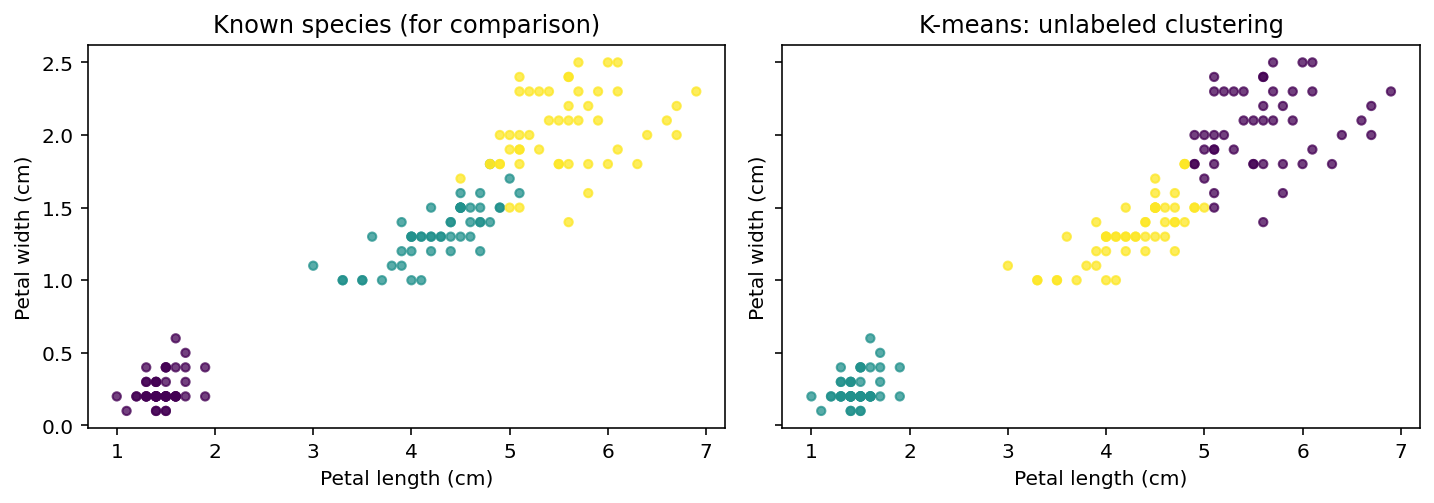

*같은 붓꽃 데이터를 실제 품종(왼쪽)과 군집화 결과(오른쪽)로 표시한 예시다. 오른쪽 군집화에는 품종 레이블을 사용하지 않았다.*

### 무엇을 비슷하다고 볼 것인가는 누가 정할까?

군집화는 숫자로 표현된 특성을 비교한다. **어떤 특성을 선택하고 어떤 단위로 표현하는지**에 따라 가까운 샘플이 달라질 수 있다. 따라서 군집 결과를 보기 전에 **'무엇이 비슷한가?'**라는 분석 기준을 먼저 생각해야 한다.

**이해 확인**

- 군집 번호와 실제 품종 이름이 항상 일치하지 않는 이유는 무엇인가?
- 같은 데이터라도 선택한 특성이 다르면 군집이 달라질 수 있는가?

## 2단계: K-평균은 어떻게 군집을 만드는가?

**K-평균(K-means)**은 먼저 군집 수 `k`를 정하고, 각 군집의 중심인 **센트로이드(centroid)**를 찾는다. 센트로이드는 군집에 들어 있는 샘플들의 **특성별 평균값**이다. 실제 샘플이 있는 위치와 같을 필요는 없다.

예를 들어 점들이 두 무리로 보인다면 `k=2`로 시작할 수 있다. 다만 눈으로 두 무리처럼 보인다는 사실만으로 `k=2`가 정답이 되는 것은 아니다.

### K-평균 알고리즘의 전체 과정

**초기화 → 할당 → 갱신 → 반복**이라는 네 동작으로 이해하라.

- **초기화:** `k`개의 센트로이드를 초기 위치에 놓는다. 초기 위치는 결과에 영향을 줄 수 있다.
- **할당:** 각 샘플에서 모든 센트로이드까지의 거리를 계산한다. **가장 가까운 중심**이 나타내는 군집에 배정한다.
- **갱신:** 같은 군집에 배정된 샘플들의 특성별 평균을 계산해 **센트로이드의 위치를 옮긴다.**
- **반복:** 새 중심으로 다시 할당하고 평균을 구한다. 배정이나 중심이 거의 변하지 않으면 멈춘다.

센트로이드가 이동하면 샘플의 소속 군집도 달라질 수 있다. 따라서 처음 한 번 분류하는 것이 아니라 **중심과 군집을 번갈아 조정**하는 과정이다.

### 처음에는 센트로이드를 어디에 놓을까?

10개의 점을 **두 군집(`k=2`)**으로 나누어 보자. 점 옆 숫자 `0`~`9`는 각 샘플을 구별하기 위한 번호다.

K-평균은 계산을 시작하기 전에 **초기 센트로이드 두 개의 위치를 정한다.** 여기서는 원리를 살펴보기 위해 `(0, 0)`과 `(6, 5)`를 **임의로 선택**했다. 아래 그림의 **빨간 X**가 초기 센트로이드다.

처음 정한 위치가 최종 군집 중심은 아니다. 어떤 점을 어느 군집에 배정하는지에 따라 이 중심은 움직인다.

두 중심까지의 거리를 비교해 **파란색(군집 0)**과 **주황색(군집 1)**으로 첫 번째 군집 배정도 함께 표시했다. **주황색은 3·4·5·8·9번, 파란색은 0·1·2·6·7번**이다. 이 색은 처음부터 주어진 정답이 아니라 **임의로 정한 두 초기 중심에 가까운 쪽으로 배정한 결과**다.


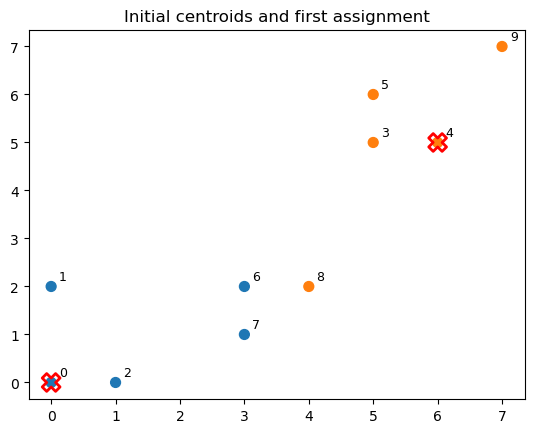

*파란 점은 군집 0, 주황 점은 군집 1의 첫 번째 배정 결과이며, 빨간 X는 임의로 정한 초기 센트로이드다.*

*0번과 4번 샘플은 초기 중심과 같은 위치에 있어 빨간 X와 겹친다. X 안쪽의 파란색·주황색은 샘플의 첫 번째 군집 배정이다.*

### 가까운 센트로이드에 배정하고 평균으로 중심을 옮긴다

각 점에서 두 센트로이드까지의 거리를 구한 다음 **더 가까운 센트로이드의 군집에 배정**한다. 첫 할당 결과는 다음과 같다.

- **군집 0:** 점 `0`, `1`, `2`, `6`, `7`
- **군집 1:** 점 `3`, `4`, `5`, `8`, `9`

이제 각 군집에 배정된 점들의 **x좌표 평균과 y좌표 평균**을 따로 계산한다. 예를 들어 군집 0의 새 중심은

$$
\left(\frac{0+0+1+3+3}{5},\ \frac{0+2+0+2+1}{5}\right)=(1.4,\ 1.0)
$$

이다. 군집 1도 같은 방법으로 계산하면 `(5.4, 5.0)`이 된다. 따라서 센트로이드는 다음과 같이 이동한다.

| 군집 | 초기 센트로이드 | 갱신된 센트로이드 |
|---|---|---|
| 0 | `(0, 0)` | `(1.4, 1.0)` |
| 1 | `(6, 5)` | `(5.4, 5.0)` |

**센트로이드는 좌표의 평균이므로 실제 샘플이 있는 위치에 놓일 필요가 없다.**

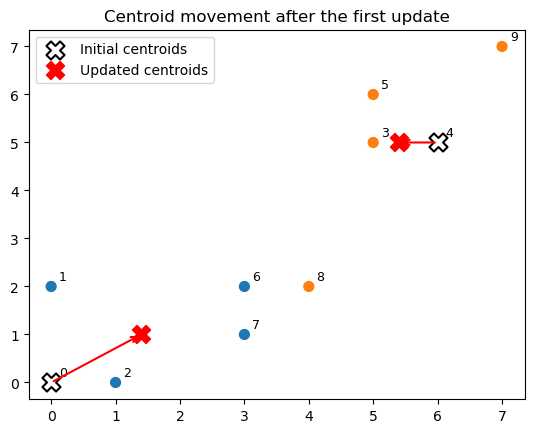

*검은색 빈 X는 초기 중심, 빨간 X는 갱신된 중심, 화살표는 이동 방향이다. 파란 점과 주황 점은 **첫 번째 할당 결과**를 나타낸다.*

### 중심을 옮긴 다음에는 무엇을 할까?

갱신된 센트로이드를 기준으로 **모든 점의 거리를 다시 계산하고 군집을 다시 배정**한다. 중심이 움직였으므로 일부 점은 이전과 다른 군집에 들어갈 수 있다.

예를 들어 그림의 **8번 점 `(4, 2)`**은 처음에는 군집 1에 속했지만, 중심을 갱신한 뒤에는 군집 0의 새 중심 `(1.4, 1.0)`에 더 가까워진다. 다음 할당에서 군집이 바뀌는 것이다.

이처럼 **할당 → 중심 갱신 → 재할당**을 반복한다. 센트로이드와 군집 배정이 더 이상 변하지 않거나 종료 조건에 도달하면 멈춘다.

### '가깝다'는 어떻게 계산할까?

K-평균은 기본적으로 **유클리드 거리**를 사용한다. 특성이 두 개라면 A와 B 사이의 거리는

$$
d(A,B)=\sqrt{(a_1-b_1)^2+(a_2-b_2)^2}
$$

이다. 특성이 더 많아도 각 특성값의 차이를 제곱하여 더한다는 원리는 같다.

**중요:** 거리 계산은 숫자의 **크기와 단위**에 영향을 받는다. 길이는 cm, 다른 특성은 수천 단위라면 값이 큰 특성이 거리에 더 크게 작용할 수 있다.

### 관성(inertia): 중심에 얼마나 모여 있는가?

K-평균은 각 샘플에서 자신이 속한 센트로이드까지의 **거리 제곱 합계**가 작아지는 방향으로 중심을 조정한다. 이 값을 **관성**이라 한다.

$$
J=\sum_{i=1}^{n} d(x_i, \mu_{c_i})^2
$$

- $x_i$: $i$번째 샘플
- $μ_{c_i}$: $i$번째 샘플이 배정된 군집의 중심

관성이 작으면 **주어진 군집 수와 특성 표현에서** 점들이 중심에 가깝다는 의미다. 관성이 작다는 사실만으로 군집의 해석이 옳다고 결론 내릴 수는 없다. 

일반적으로 군집 수가 커질 수록 관성은 작아진다. 따라서 원래 3개의 군집이 적당하다 하더라도 4개 이상의 군집으로 나누면 관성은 기본적으로 작아진다.

### 초기 중심과 반복 실행

초기 센트로이드의 선택이 달라지면 다른 군집 결과에 도달할 수 있다. 따라서 보통 한 번의 초기값에만 의존하지 않는다.

| 설정 | 의미 |
|---|---|
| `n_clusters=k` | 만들 군집의 수 |
| `n_init=10` | 서로 다른 초기화로 여러 번 시도하고 관성이 작은 결과를 선택 |
| `random_state=42` | 실행 결과를 재현하기 위한 무작위 기준 |

`KMeans`는 기본적으로 초기 중심을 분산해서 선택하려는 **k-means++** 방식을 사용한다. 이는 초기화 문제를 완전히 없애지는 않는다.

### 학습·배정·거리 확인

| 메서드·속성 | 의미 |
|---|---|
| `fit(X)` | 입력 특성 `X`를 사용해 센트로이드를 학습 |
| `fit_predict(X)` | 학습한 뒤 각 샘플의 군집 번호 반환 |
| `cluster_centers_` | 학습된 `k`개 센트로이드의 좌표 |
| `inertia_` | 학습 데이터의 관성 |
| `transform(X)` | 각 샘플에서 모든 센트로이드까지의 거리 |
| `predict(X_new)` | **중심을 다시 학습하지 않고** 새 샘플을 기존 군집에 배정 |

**이해 확인**

- 왜 센트로이드는 실제 샘플 위치가 아닐 수 있는가?
- `fit_predict()`와 `predict()`의 차이를 설명해 보라.
- 센트로이드가 갱신되면 일부 샘플의 군집이 달라질 수 있는 이유는 무엇인가?

## 3단계: 같은 데이터라도 특성의 표현이 달라지면?

### 거리 계산에서 숫자가 큰 특성이 왜 문제가 될까?

네 가게를 **하루 방문객 수**와 **고객 만족도(5점 만점)**라는 두 특성으로 비교한다고 하자.

| 가게 | 하루 방문객 수 | 만족도 |
|---|---:|---:|
| A | 100명 | 4점 |
| B | 200명 | 4점 |
| C | 100명 | 3점 |
| D | 200명 | 3점 |

A를 기준으로 비교해 보자. B는 만족도가 같지만 방문객이 100명 더 많고, C는 방문객이 같지만 만족도가 1점 낮다.

K-평균에서 사용하는 **유클리드 거리**를 그대로 계산하면 다음과 같다.

$$
d(A,B)=\sqrt{(100-200)^2+(4-4)^2}=100
$$

$$
d(A,C)=\sqrt{(100-100)^2+(4-3)^2}=1
$$

거리만 보면 **A와 C가 A와 B보다 100배 가깝다.** 만족도의 1점 차이보다 방문객 수의 100명 차이가 훨씬 크게 반영된 것이다. 그러나 방문객 100명과 만족도 1점을 이렇게 비교하는 것이 타당할까?

이 문제를 완화하는 한 가지 방법이 **표준화(StandardScaler)**이다. 표준화는 각 특성에서 평균을 빼고 표준편차로 나누는 방법이다.

$$
\text{표준화한 값}=\frac{\text{원래 값}-\text{해당 특성의 평균}}{\text{해당 특성의 표준편차}}
$$

이 네 가게에서 방문객 수의 평균은 150명, 표준편차는 50명이다. 만족도의 평균은 3.5점, 표준편차는 0.5점이다. 따라서 A, B, C의 좌표는 다음과 같이 변한다.

| 가게 | 표준화한 방문객 수 | 표준화한 만족도 |
|---|---:|---:|
| A | $(100-150)/50=-1$ | $(4-3.5)/0.5=1$ |
| B | $(200-150)/50=1$ | $(4-3.5)/0.5=1$ |
| C | $(100-150)/50=-1$ | $(3-3.5)/0.5=-1$ |

이제 거리를 다시 계산해 보자.

$$
d(A,B)=\sqrt{(-1-1)^2+(1-1)^2}=2
$$

$$
d(A,C)=\sqrt{(-1+1)^2+(1+1)^2}=2
$$

**표준화 전에는 100과 1이었던 두 거리가 표준화 후에는 모두 2가 되었다.** 방문객 수와 만족도가 각자 데이터에서 얼마나 변하는지를 기준으로 거리를 계산하기 때문이다.

표준화가 두 특성을 언제나 똑같이 중요하게 만드는 것은 아니다. **숫자의 단위와 범위 때문에 한 특성이 일방적으로 거리를 좌우하는 문제를 줄이는 것**이다.

### 전체 규모보다 구성 비율이 중요할 때는?

이번에는 판매점 세 곳에서 **상품 1과 상품 2의 판매건수**를 조사했다고 하자.

| 판매점 | 상품 1 | 상품 2 | 전체 판매건수 |
|---|---:|---:|---:|
| P | 800건 | 200건 | 1,000건 |
| Q | 80건 | 20건 | 100건 |
| R | 20건 | 80건 | 100건 |

P와 Q는 판매량이 10배 차이 나지만, **상품 1이 80%, 상품 2가 20%**라는 구성은 같다. 반면 Q와 R은 전체 판매건수가 같지만 어떤 상품이 많이 팔리는지가 정반대이다.

그런데 원래 건수로 거리를 계산하면 다음과 같다.

$$
d(P,Q)=\sqrt{(800-80)^2+(200-20)^2}\approx742.2
$$

$$
d(Q,R)=\sqrt{(80-20)^2+(20-80)^2}\approx84.9
$$

**원래 건수로는 Q와 R이 더 가깝다.** 판매 *규모*를 중요하게 반영했기 때문이다. 하지만 상품별 판매 *구성*이 비슷한 가게를 찾는다면 P와 Q를 같은 유형으로 보는 것이 자연스럽다.

이럴 때는 각 판매점의 두 값을 **그 판매점의 전체 판매건수로 나누어 비중**으로 바꿀 수 있다.

| 판매점 | 상품 1 비중 | 상품 2 비중 |
|---|---:|---:|
| P | $800/1000=0.8$ | $200/1000=0.2$ |
| Q | $80/100=0.8$ | $20/100=0.2$ |
| R | $20/100=0.2$ | $80/100=0.8$ |

비중으로 변환한 뒤의 거리는 다음과 같다.

$$
d(P,Q)=\sqrt{(0.8-0.8)^2+(0.2-0.2)^2}=0
$$

$$
d(Q,R)=\sqrt{(0.8-0.2)^2+(0.2-0.8)^2}\approx0.85
$$

이제 **P와 Q가 같은 구성을 가진다는 사실이 거리 0으로 나타난다.** 대신 P와 Q의 전체 판매량이 10배 차이 난다는 정보는 비중에서 사라졌다.

### 표준화와 비중 변환은 무엇이 다를까?

| 방법 | 무엇으로 나누는가? | 남기려는 정보 | 주의할 점 |
|---|---|---|---|
| **표준화** | 각 **특성(열)**의 표준편차 | 특성별 상대적 차이 | 전체 규모의 차이를 제거하지는 않음 |
| **비중 변환** | 각 **샘플(행)**의 합계 | 항목 간 구성 비율 | 전체 규모 정보가 사라짐 |

**어느 방법이 항상 더 좋은 것은 아니다.** 방문객 수가 중요한 분석이라면 규모를 남겨야 하고, 상품 판매 구성만 비교하려면 비중 변환이 알맞을 수 있다. 무엇을 비슷하다고 볼 것인지 먼저 결정해야 한다.

### 특성 설계에서 판단할 것

군집화 전에 다음 질문을 확인하자.

- **샘플:** 한 행은 가게 하나인가, 사람 하나인가, 다른 대상인가?
- **특성:** 서로 다른 열의 값은 어떤 단위인가? 숫자가 큰 열이 거리를 지배하지 않는가?
- **분석 목적:** 총량이 비슷한 대상을 찾으려는가, 구성 비율이 비슷한 대상을 찾으려는가?
- **잃는 정보:** 비중 변환으로 규모를 지웠다면, 군집을 해석할 때 원래 건수도 함께 살펴볼 필요가 있지 않은가?

**이해 확인**

- 첫 번째 예시에서 원래 값으로 계산한 A–B 거리와 A–C 거리가 크게 달랐던 이유를 설명해 보라.
- 두 번째 예시에서 P–Q 거리가 비중 변환 후 0이 된 이유는 무엇인가?
- 판매점의 **매출 규모**에 따라 군집을 나누려 한다면 비중만 사용하는 것이 적절할까? 이유를 설명해 보라.

## 4단계: 군집 수를 어떻게 판단할까?

K-평균에서는 `k`를 **학습 전에 지정**해야 한다. 데이터 안에 실제 군집이 몇 개인지 알려 주는 정답이 없는 경우가 많으므로, 여러 후보를 비교하고 결과를 해석해야 한다.

### 관성 곡선과 엘보 방법

`k`를 늘리면 군집마다 더 적은 샘플을 담당하게 되어 관성이 일반적으로 줄어든다. 그래서 **관성이 가장 작다는 이유만으로 큰 `k`를 선택할 수는 없다.**

관성 감소가 크게 둔화되는 지점을 엘보(elbow)라 부르며 하나의 후보로 검토한다. 하지만 모든 데이터에 명확한 굽은 지점이 나타나는 것은 아니다.

### 실루엣 점수는 무엇을 말해 주는가?

실루엣 계수는 **같은 군집에 속한 샘플과 얼마나 가깝고, 다른 군집의 샘플과 얼마나 떨어져 있는지**를 함께 비교한다.

- `a`: 자신이 속한 군집의 다른 샘플들과의 평균 거리
- `b`: 가장 가까운 **다른 군집**에 속한 샘플들과의 평균 거리

$$
s=\frac{b-a}{\max(a,b)}
$$

- **1에 가까움:** 자기 군집과 더 가깝고 다른 군집에서 떨어져 있음
- **0에 가까움:** 군집 경계 근처에 있음
- **음수:** 다른 군집의 샘플들과 평균적으로 더 가까울 수 있음

데이터 전체의 실루엣 점수는 샘플별 계수의 **평균**이다. 군집이 하나뿐이면 계산할 수 없다.

### 높은 실루엣 점수가 곧 '옳은 군집'일까?

**그렇지 않다.** 실루엣 점수는 널리 사용하는 **내부 평가 지표**이지만 군집에 외부의 정답을 부여하지는 않는다. 특히 유클리드 거리에서 **조밀하고 서로 분리된 군집**을 선호하므로, 다른 형태의 군집이나 세부 집단을 발견하는 목적과 항상 일치하지 않는다.

따라서 여러 `k`의 실루엣 점수를 계산해 가장 높은 값을 **후보로 자동 선택**할 수는 있지만, 다음 사항도 확인해야 한다.

- 군집에 샘플이 얼마나 분포하는가? 지나치게 작은 군집은 없는가?
- 군집별 특성이 실제로 구분되고 **해석 가능한가?**
- `k`를 조금 바꾸면 중요한 결론이 달라지는가?
- **입력 특성이나 전처리 방법**을 바꾸면 결과가 크게 달라지는가?

실루엣 점수가 가장 높은 `k`는 **선택한 후보와 특성 표현 안에서의 최고 점수**일 뿐, 실제 세계의 참된 군집 수라고 단정해서는 안 된다.

### 군집 결과를 검증하는 자세

군집 이름은 알고리즘이 알려주지 않는다. 먼저 **군집별 특성의 평균과 분포**를 살펴보고, 중심에 가까운 전형적인 샘플과 중심에서 먼 샘플도 비교하라. 같은 군집 안에도 서로 다른 사례가 있을 수 있다.

**이해 확인**

- 관성만 보고 `k`를 결정하기 어려운 이유는 무엇인가?
- 실루엣 점수 최고값을 자동 선택했더라도 어떤 추가 확인이 필요한가?

## 5단계: K-평균의 한계는 무엇인가?

K-평균은 계산이 비교적 간단하고 센트로이드로 군집을 설명하기 쉽다. 그러나 **모든 데이터에 잘 맞는 군집화 알고리즘은 아니다.**

- **군집 수 사전 지정:** 적절한 `k`를 미리 알기 어렵다.
- **모양의 한계:** 중심 주변에 비교적 둥글게 모인 군집에는 잘 맞지만, 굽은 모양이나 길게 늘어진 구조를 제대로 구분하지 못할 수 있다.
- **크기·밀도의 차이:** 군집마다 크기나 밀도가 크게 다르면 작은 집단을 잘못 나눌 수 있다.
- **이상치와 초기화:** 멀리 떨어진 일부 점이나 초기 중심에 결과가 영향을 받을 수 있다.
- **특성의 단위:** 스케일이 다른 특성을 그대로 넣으면 거리 판단이 치우칠 수 있다.

따라서 **관성이 낮거나 실루엣 점수가 높아도** 관심 있는 구조를 제대로 찾았는지 별도로 판단해야 한다.

### 다른 군집화 알고리즘도 있다

- **DBSCAN:** 밀집한 점들을 이어서 군집을 찾는다. K-평균과 달리 굽은 형태의 군집에도 적용할 수 있으며, 일부 점을 잡음으로 구분할 수 있다.
- **가우스 혼합 모델(GMM):** 데이터가 여러 확률분포의 혼합이라고 보고 각 분포에 대한 소속 정도를 추정한다. 타원형 군집을 표현할 수 있다.

두 방법에도 각자의 가정과 매개변수 선택 문제가 있다. **어느 방법이 더 적절한지는 데이터의 구조와 분석 목적에 따라 달라진다.**

## 이론 정리

| 핵심 개념 | 기억할 내용 |
|---|---|
| 비지도 학습 | 정답 레이블 없이 데이터의 구조를 탐색한다. |
| K-평균 알고리즘 | 초기화 → 가까운 중심에 할당 → 평균으로 중심 갱신 → 반복 |
| 센트로이드 | 군집 샘플의 특성별 평균이며 실제 점이 아닐 수 있다. |
| 관성 | 샘플과 자기 센트로이드 사이 거리 제곱의 합계 |
| 전처리 | 특성 단위·규모·비중 표현에 따라 거리와 군집 결과가 달라진다. |
| 실루엣 점수 | 군집 내 가까움과 군집 간 분리 정도를 평가하는 **보조 지표** |
| 군집 해석 | 번호보다 특성 분포, 대표 사례, 비전형 사례를 확인한다. |
| K-평균의 한계 | 군집 수·모양·밀도·이상치·스케일에 민감하다. |

**스스로 점검하라**

- 센트로이드 갱신 과정을 숫자로 예를 들어 설명할 수 있는가?
- 관성이 계속 줄어드는 것만으로 좋은 군집 수를 정할 수 있는가?
- 실루엣 점수가 높더라도 잘못된 결론에 이를 수 있는 이유는 무엇인가?
- 어떤 데이터에서는 K-평균 대신 다른 군집화 방법을 검토해야 하는가?